In [5]:
import tensorflow 
from sklearn.datasets import make_moons
import numpy as np 
import matplotlib.pyplot as plt 
from mlxtend.plotting import plot_decision_regions
from sklearn.datasets import make_moons
import seaborn as sns 

from tensorflow.keras.layers import Dense , Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Sequential

In [10]:
print(tensorflow.config.list_physical_devices('GPU'))


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
X, y = make_moons(100, noise= 0.25 , random_state = 42 )


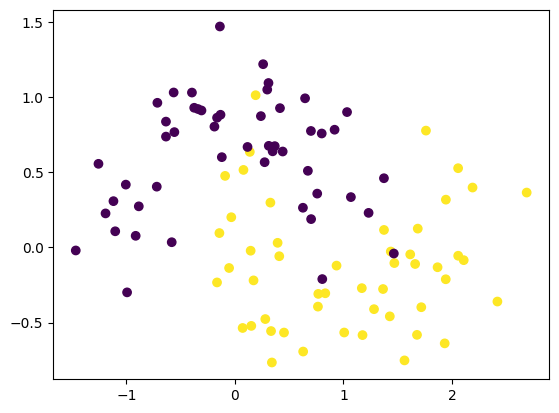

In [7]:
plt.scatter(X[: , 0], X[ : , 1 ], c=y)
plt.show()

# Without Activation Function

In [ ]:
model1 = Sequential()
# Linear Activation function is same as no activation function 
model1.add(Dense(128, input_dim = 2 , activation = 'linear'))
model1.add(Dense(128, activation = 'linear'))
model1.add(Dense(1, activation = 'sigmoid'))

model1.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 128)               384       
                                                                 
 dense_1 (Dense)             (None, 128)               16512     
                                                                 
 dense_2 (Dense)             (None, 1)                 129       
                                                                 
Total params: 17,025
Trainable params: 17,025
Non-trainable params: 0
_________________________________________________________________


In [12]:
adam = Adam(learning_rate = 0.01)
model1.compile(loss = 'binary_crossentropy', optimizer = adam, metrics = ['accuracy'])

with tensorflow.device('/GPU:0'):
    history1 = model1.fit(
        X,
        y,
        epochs= 500 ,
        batch_size=256,
        validation_split=0.2,
        verbose = 1
    )

Epoch 1/500
1/1 [==============================] - 0s 323ms/step - loss: 0.3076 - accuracy: 0.8625 - val_loss: 0.3910 - val_accuracy: 0.8000
Epoch 2/500
1/1 [==============================] - 0s 24ms/step - loss: 0.3199 - accuracy: 0.8500 - val_loss: 0.4680 - val_accuracy: 0.8000
Epoch 3/500
1/1 [==============================] - 0s 23ms/step - loss: 0.3262 - accuracy: 0.8625 - val_loss: 0.4198 - val_accuracy: 0.8000
Epoch 4/500
1/1 [==============================] - 0s 23ms/step - loss: 0.3103 - accuracy: 0.8750 - val_loss: 0.4100 - val_accuracy: 0.8000
Epoch 5/500
1/1 [==============================] - 0s 23ms/step - loss: 0.3234 - accuracy: 0.8875 - val_loss: 0.4080 - val_accuracy: 0.8000
Epoch 6/500
1/1 [==============================] - 0s 22ms/step - loss: 0.3146 - accuracy: 0.8750 - val_loss: 0.4205 - val_accuracy: 0.8000
Epoch 7/500
1/1 [==============================] - 0s 44ms/step - loss: 0.3111 - accuracy: 0.8625 - val_loss: 0.4333 - val_accuracy: 0.8000
Epoch 8/500
1/1 [==

9600/9600 [==============================] - 7s 760us/step


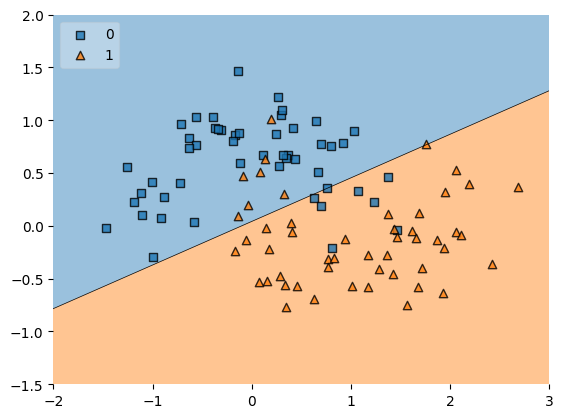

In [ ]:
plot_decision_regions(X, y.astype('int'), clf = model1, legend = 2 )
plt.xlim(-2, 3 )
plt.ylim(-1.5 , 2)
plt.show()
# You can see here the model decision boundary is a line & it cannot make a curve as a decision boundary , so clearly the model is a linear model.

# With Activation Function 

In [15]:
model2 = Sequential()

model2.add(Dense(128, input_dim = 2 , activation = 'relu'))
model2.add(Dense(128, activation = 'relu'))
model2.add(Dense(1, activation = 'sigmoid'))

model1.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 128)               384       
                                                                 
 dense_1 (Dense)             (None, 128)               16512     
                                                                 
 dense_2 (Dense)             (None, 1)                 129       
                                                                 
Total params: 17,025
Trainable params: 17,025
Non-trainable params: 0
_________________________________________________________________


In [16]:
adam = Adam(learning_rate = 0.01)
model2.compile(loss = 'binary_crossentropy', optimizer = adam, metrics = ['accuracy'])

with tensorflow.device('/GPU:0'):
    history1 = model2.fit(
        X,
        y,
        epochs= 500 ,
        batch_size=256,
        validation_split=0.2,
        verbose = 1
    )

Epoch 1/500
1/1 [==============================] - 0s 358ms/step - loss: 0.6793 - accuracy: 0.7625 - val_loss: 0.5589 - val_accuracy: 0.7500
Epoch 2/500
1/1 [==============================] - 0s 29ms/step - loss: 0.5315 - accuracy: 0.8125 - val_loss: 0.4922 - val_accuracy: 0.8000
Epoch 3/500
1/1 [==============================] - 0s 26ms/step - loss: 0.4329 - accuracy: 0.8000 - val_loss: 0.4486 - val_accuracy: 0.8000
Epoch 4/500
1/1 [==============================] - 0s 30ms/step - loss: 0.3588 - accuracy: 0.8500 - val_loss: 0.4296 - val_accuracy: 0.8000
Epoch 5/500
1/1 [==============================] - 0s 32ms/step - loss: 0.3171 - accuracy: 0.8750 - val_loss: 0.4330 - val_accuracy: 0.8000
Epoch 6/500
1/1 [==============================] - 0s 28ms/step - loss: 0.3078 - accuracy: 0.8750 - val_loss: 0.4515 - val_accuracy: 0.8000
Epoch 7/500
1/1 [==============================] - 0s 32ms/step - loss: 0.3090 - accuracy: 0.9000 - val_loss: 0.4809 - val_accuracy: 0.8000
Epoch 8/500
1/1 [==

9600/9600 [==============================] - 11s 1ms/step


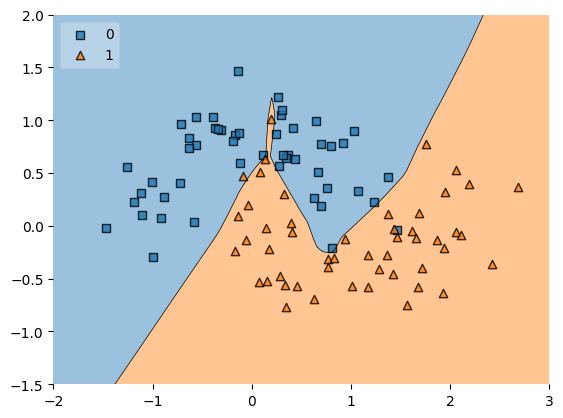

In [ ]:
plot_decision_regions(X, y.astype('int'), clf = model2, legend = 2 )
plt.xlim(-2, 3 )
plt.ylim(-1.5 , 2)
plt.show()
# You can see here the model decision boundary is a curve, so clearly the model is a Non - linear model that can capture non linear patterns in data.